<a href="https://colab.research.google.com/github/ady-aashish/computational-immune-profiling/blob/main/Project_1_Computational_Immune_Profiling_%26_Biomarker_Discovery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = {
    "Sample": ["S01", "S02", "S03", "S04", "S05",
               "S06", "S07", "S08", "S09", "S10"],

    "T_cells": [4200, 3900, 4500, 5200, 4800,
                4100, 5500, 4700, 4300, 5000],

    "B_cells": [1800, 2100, 1700, 2300, 1900,
                2000, 2400, 1850, 2200, 2100],

    "NK_cells": [1200, 1400, 1100, 1600, 1300,
                 1500, 1700, 1250, 1450, 1550],

    "Monocytes": [1500, 1300, 1600, 1800, 1700,
                  1400, 1900, 1550, 1650, 1750],

    "IL6": [12, 18, 10, 35, 28,
            15, 42, 22, 17, 31],

    "TNF": [8, 11, 7, 24, 20,
            10, 29, 16, 12, 21],

    "IFNg": [15, 18, 13, 30, 25,
             17, 34, 21, 19, 28],

    "IL10": [5, 7, 4, 9, 8,
             6, 11, 7, 6, 10]
}

df = pd.DataFrame(data)

df
print("Number of samples:", len(df))
print("Number of variables:", len(df.columns))

df.head()

Number of samples: 10
Number of variables: 9


,Sample,T_cells,B_cells,NK_cells,Monocytes,IL6,TNF,IFNg,IL10
0,S01,4200,1800,1200,1500,12,8,15,5
1,S02,3900,2100,1400,1300,18,11,18,7
2,S03,4500,1700,1100,1600,10,7,13,4
3,S04,5200,2300,1600,1800,35,24,30,9
4,S05,4800,1900,1300,1700,28,20,25,8


In [3]:
df.describe()

,T_cells,B_cells,NK_cells,Monocytes,IL6,TNF,IFNg,IL10
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,4620.000000,2035.000000,1405.000000,1615.000000,23.000000,15.800000,22.000000,7.300000
std,513.809303,226.139092,190.685896,184.164781,10.593499,7.420692,6.944222,2.213594
min,3900.000000,1700.000000,1100.000000,1300.000000,10.000000,7.000000,13.000000,4.000000
25%,4225.000000,1862.500000,1262.500000,1512.500000,15.500000,10.250000,17.250000,6.000000
50%,4600.000000,2050.000000,1425.000000,1625.000000,20.000000,14.000000,20.000000,7.000000
75%,4950.000000,2175.000000,1537.500000,1737.500000,30.250000,20.750000,27.250000,8.750000
max,5500.000000,2400.000000,1700.000000,1900.000000,42.000000,29.000000,34.000000,11.000000


In [4]:
immune_cells = ["T_cells", "B_cells", "NK_cells", "Monocytes"]

df["Total_immune_cells"] = df[immune_cells].sum(axis=1)

df[["Sample", "Total_immune_cells"]]

,Sample,Total_immune_cells
0,S01,8700
1,S02,8700
2,S03,8900
3,S04,10900
4,S05,9700
5,S06,9000
6,S07,11500
7,S08,9350
8,S09,9600
9,S10,10400


In [5]:
for cell in immune_cells:
    df[cell + "_percent"] = (
        df[cell] / df["Total_immune_cells"] * 100
    )

df.head()

,Sample,T_cells,B_cells,NK_cells,Monocytes,IL6,TNF,IFNg,IL10,Total_immune_cells,T_cells_percent,B_cells_percent,NK_cells_percent,Monocytes_percent
0,S01,4200,1800,1200,1500,12,8,15,5,8700,48.275862,20.689655,13.793103,17.241379
1,S02,3900,2100,1400,1300,18,11,18,7,8700,44.827586,24.137931,16.091954,14.942529
2,S03,4500,1700,1100,1600,10,7,13,4,8900,50.561798,19.101124,12.359551,17.977528
3,S04,5200,2300,1600,1800,35,24,30,9,10900,47.706422,21.100917,14.678899,16.513761
4,S05,4800,1900,1300,1700,28,20,25,8,9700,49.484536,19.587629,13.402062,17.525773


In [6]:
df["Dominant_cell"] = df[immune_cells].idxmax(axis=1)

df[["Sample", "Dominant_cell"]]
mean_cells = df[immune_cells].mean()

print(mean_cells)

T_cells      4620.0
B_cells      2035.0
NK_cells     1405.0
Monocytes    1615.0
dtype: float64


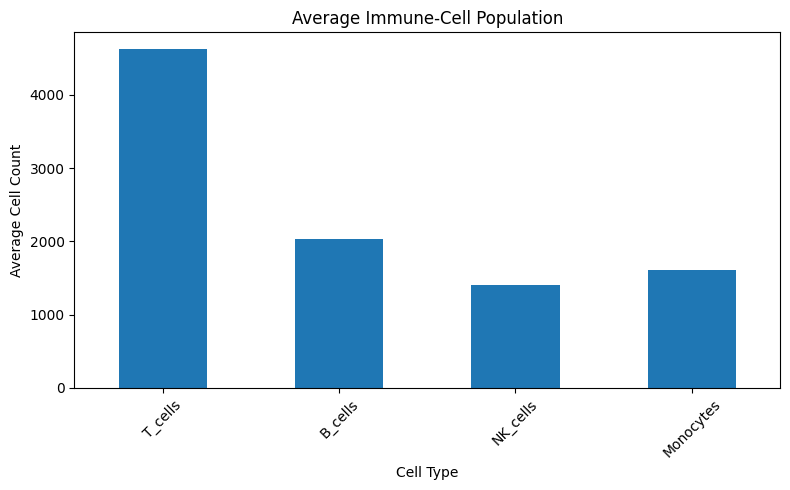

In [7]:
mean_cells.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Immune-Cell Population")
plt.xlabel("Cell Type")
plt.ylabel("Average Cell Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
cytokines = ["IL6", "TNF", "IFNg", "IL10"]

cytokine_means = df[cytokines].mean()

print(cytokine_means)

IL6     23.0
TNF     15.8
IFNg    22.0
IL10     7.3
dtype: float64


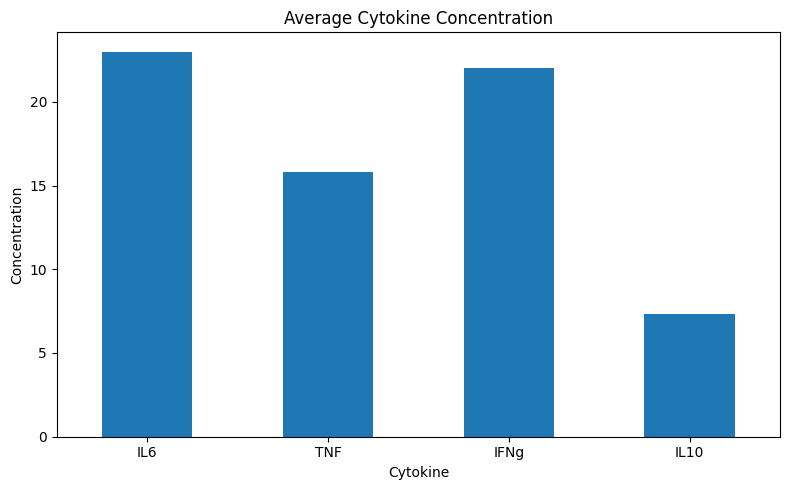

In [9]:
cytokine_means.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Cytokine Concentration")
plt.xlabel("Cytokine")
plt.ylabel("Concentration")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [10]:
df["Inflammatory_score"] = (
    df["IL6"] +
    df["TNF"] +
    df["IFNg"]
) / 3

df[["Sample", "Inflammatory_score"]]


,Sample,Inflammatory_score
0,S01,11.666667
1,S02,15.666667
2,S03,10.000000
3,S04,29.666667
4,S05,24.333333
5,S06,14.000000
6,S07,35.000000
7,S08,19.666667
8,S09,16.000000
9,S10,26.666667


In [11]:
def classify_inflammation(score):

    if score < 15:
        return "Low"

    elif score < 25:
        return "Moderate"

    else:
        return "High"


df["Inflammation_category"] = df["Inflammatory_score"].apply(
    classify_inflammation
)

df[[
    "Sample",
    "Inflammatory_score",
    "Inflammation_category"
]]

,Sample,Inflammatory_score,Inflammation_category
0,S01,11.666667,Low
1,S02,15.666667,Moderate
2,S03,10.000000,Low
3,S04,29.666667,High
4,S05,24.333333,Moderate
5,S06,14.000000,Low
6,S07,35.000000,High
7,S08,19.666667,Moderate
8,S09,16.000000,Moderate
9,S10,26.666667,High


In [12]:
df["Inflammation_category"].value_counts()

,count
Inflammation_category,
Moderate,4
Low,3
High,3


In [13]:
correlation_matrix = df[cytokines].corr()

correlation_matrix


,IL6,TNF,IFNg,IL10
IL6,1.000000,0.996467,0.996870,0.966608
TNF,0.996467,1.000000,0.994009,0.951043
IFNg,0.996870,0.994009,1.000000,0.968591
IL10,0.966608,0.951043,0.968591,1.000000


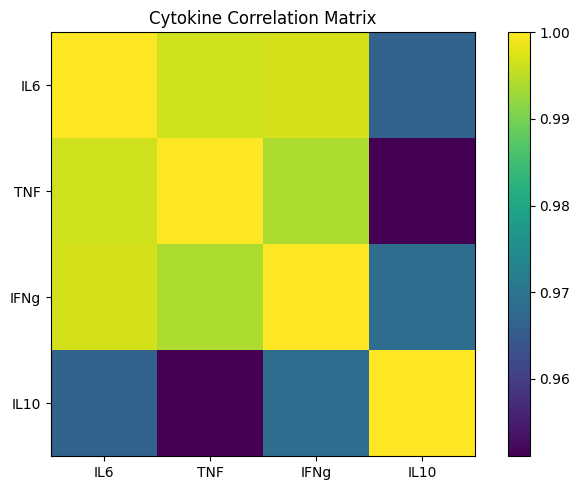

In [14]:
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(cytokines)),
    cytokines
)

plt.yticks(
    range(len(cytokines)),
    cytokines
)

plt.title("Cytokine Correlation Matrix")

plt.tight_layout()
plt.show()

In [15]:
df.sort_values(
    "Inflammatory_score",
    ascending=False
)[[
    "Sample",
    "IL6",
    "TNF",
    "IFNg",
    "Inflammatory_score",
    "Inflammation_category"
]]

,Sample,IL6,TNF,IFNg,Inflammatory_score,Inflammation_category
6,S07,42,29,34,35.000000,High
3,S04,35,24,30,29.666667,High
9,S10,31,21,28,26.666667,High
4,S05,28,20,25,24.333333,Moderate
7,S08,22,16,21,19.666667,Moderate
8,S09,17,12,19,16.000000,Moderate
1,S02,18,11,18,15.666667,Moderate
5,S06,15,10,17,14.000000,Low
0,S01,12,8,15,11.666667,Low
2,S03,10,7,13,10.000000,Low


In [16]:
df.to_csv(
    "immune_profiling_results.csv",
    index=False
)

print("Results saved successfully.")


Results saved successfully.
